**LABORATORIO: Introducción a los Biopotenciales**

ECG y EMG - Bioseñales y Sistemas

Universidad de Antioquia - Bioingeniería

Integrantes:

* Valentina García Obando Cc 1000539432
* Mariana Giraldo Gil CC 





**5.1 Realice un esquema donde se describan y expliquen las diferentes etapas del registro de biopotenciales, desde la generación de los potenciales de acción hasta su adquisición por el equipo. Adicionalmente, describa a grandes rasgos los componentes de un equipo de adquisición.**

Imagen[1]
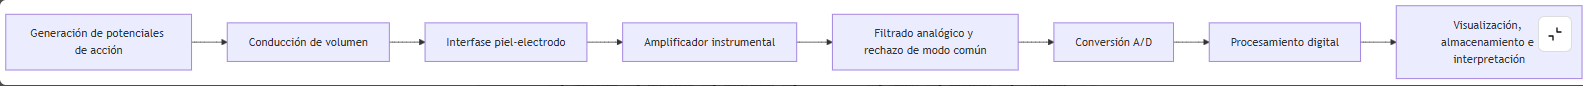

El registro de un biopotencial es una cadena de transducción que va desde la fisiología celular hasta una señal digital interpretable. Las membranas excitables generan potenciales de acción mediante intercambio iónico: en el ECG, la señal refleja la despolarización y repolarización del miocardio; en el EMG de superficie, resulta de la suma de los potenciales de múltiples unidades motoras. Estos campos eléctricos se propagan por conducción de volumen a través de tejidos con distintas propiedades eléctricas (músculo, grasa, piel y fluidos), llegando a la superficie ya atenuados y condicionados por la geometría anatómica, la posición de los electrodos y la calidad del contacto eléctrico[1].

Una vez que el campo eléctrico alcanza la piel, los electrodos lo convierten en una señal medible. Esta señal entra al front-end analógico, donde un amplificador de instrumentación con alta impedancia de entrada y alto CMRR amplifica las diferencias de potencial (del orden de µV a mV) minimizando interferencias de modo común, especialmente la red eléctrica. En ECG se complementa con el circuito de pierna derecha conducida para mejorar aún más el rechazo al ruido de red. Posteriormente, la señal se filtra analógicamente (paso alto para eliminar derivas lentas, paso bajo para limitar ruido de alta frecuencia y anti-alias antes de la digitalización) y finalmente se convierte a formato digital para su almacenamiento, detección de eventos y extracción de características[1].

Un equipo de adquisición de biopotenciales está conformado por: electrodos de registro y referencia, cables de conexión, módulo de aislamiento eléctrico, amplificador de instrumentación, filtros analógicos, convertidor A/D, microcontrolador y una interfaz de visualización o almacenamiento. En el sEMG cobran especial importancia la distancia interelectrodo, la orientación respecto a las fibras musculares y la fijación mecánica del sensor. Es importante destacar que estas etapas no son independientes: un mal contacto electrodo–piel o una ganancia mal ajustada comprometen todo el procesamiento posterior. El equipo no genera la señal, sino que debe preservar con fidelidad un fenómeno fisiológico pequeño y vulnerable a artefactos[2].


**5.2 Presente una tabla con las principales fuentes de ruido en el registro de biopotenciales. Determine ¿Cuáles de estas fuentes de ruido son estáticas o variantes en el tiempo? Indique que estrategias se utilizan para controlar o eliminar dicha fuente de ruido.**

En el registro de biopotenciales coexisten perturbaciones de naturaleza física diferente, que pueden clasificarse en tres grupos según su comportamiento temporal: componentes cuasiestáticos o de deriva lenta (offsets de electrodo, potenciales de media celda, desbalance de impedancias); perturbaciones periódicas casi estacionarias (interferencia de red eléctrica a 50/60 Hz); y artefactos no estacionarios (movimiento de electrodos, balanceo de cables, contracciones musculares no deseadas)[3]. 
Esta clasificación es relevante porque cada fuente exige una estrategia de control distinta, y la prevención física debe priorizarse sobre la corrección digital posterior[3]:

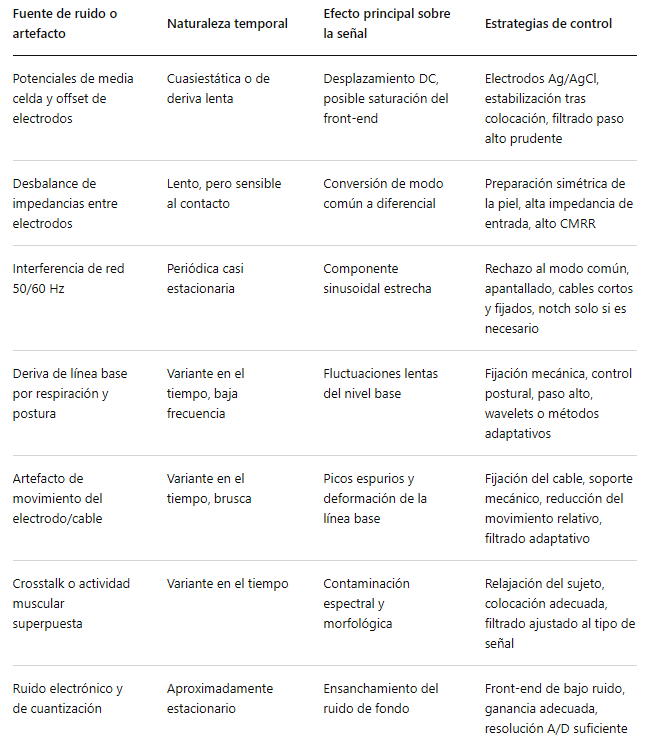

En ECG, las fuentes más críticas son la deriva de línea base y el ruido muscular, pues pueden comprometer el análisis del segmento ST, la detección de picos R y la interpretación de ondas T y Q. En EMG, el artefacto de movimiento y la interferencia de red afectan la amplitud de la envolvente y las métricas espectrales. Por ello, la estrategia óptima combina buenas prácticas de adquisición (preparación cutánea, fijación de electrodos, reducción de lazos de cable y amplificación diferencial) con un filtrado cauteloso y específico, ya que un filtrado demasiado agresivo puede eliminar información fisiológica real[4].

**5.3 Describa ¿Cuál es la problemática asociada al acoplamiento piel-electrodo? ¿Cuáles estrategias se utilizan para mejorarla? Además, responda ¿Por qué el acoplamiento piel-electrodo constituye la etapa más crítica en el registro de señales de superficie (sEMG, EEG, ECG)?**

La interfaz piel–electrodo no es un contacto simple, sino una estructura electroquímica compleja formada por el estrato córneo (barrera resistiva y capacitiva), el gel electrolito y el potencial de media celda del material del electrodo, cuya impedancia varía con la presión, hidratación, movimiento y el tiempo transcurrido tras la colocación. Esta interfaz se modela mediante resistencias y capacitancias distribuidas no lineales, lo que implica que el sistema no mide únicamente la fuente fisiológica, sino también el comportamiento eléctrico del propio contacto[5]

La interfaz piel-electrodo presenta tres problemas principales. Primero, introduce ruido y deriva, originados principalmente en la interfase electrolito-piel y dependientes del gel conductor y las propiedades cutáneas del sujeto. Segundo, la impedancia de contacto varía con el movimiento, generando artefactos que deforman la línea base y degradan la relación señal-ruido. Tercero, la asimetría entre impedancias de los canales de entrada convierte el ruido de modo común (como la interferencia de red) en señal diferencial, reduciendo la eficacia real del CMRR del amplificador. Estos problemas son especialmente críticos en registros de superficie porque la señal útil ya llega muy atenuada a la piel[5].

El acoplamiento piel–electrodo es la etapa más crítica del registro de superficie porque es el primer punto no fisiológico de la cadena de adquisición: cualquier distorsión introducida ahí será amplificada y digitalizada junto con la señal útil. Algunos errores en esta interfaz (saturación, pérdida de contacto o deformación morfológica) no son recuperables mediante procesamiento posterior. Las estrategias de mejora incluyen: limpieza y ligera abrasión de la piel, uso de electrodos Ag/AgCl, espera para estabilización del contacto, control del gel conductor y fijación del cable para reducir artefactos por movimiento. Estudios recientes confirman que la hidratación, el material del electrodo y el soporte mecánico afectan de forma apreciable la impedancia de contacto, lo que refuerza que la calidad del registro comienza antes del amplificador[6].

**5.4 Análisis de la Variabilidad de la frecuencia cardíaca (HRV)**

1. Detectar los picos R utilizando la función de la librería NeuroKit y de Detectors. ¿Cuál de los algoritmos detecta mejor los picos R?

In [ ]:
# Instalación
# !pip install neurokit2 hrv-analysis
# !pip install git+https://github.com/berndporr/py-ecg-detectors.git

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import neurokit2 as nk
from ecgdetectors import Detectors
from scipy.signal import butter, filtfilt, find_peaks

# 1. Cargar la señal
data = pd.read_csv("señal_ECG.csv")
tiempo = data.iloc[:, 0].to_numpy(dtype=float)
signal = data.iloc[:, 1].to_numpy(dtype=float)

# 2. Frecuencia de muestreo calculada a partir de la columna de tiempo (no supuesta)
fs = int(round(1 / np.mean(np.diff(tiempo))))
print(f"Frecuencia de muestreo: {fs} Hz")
print(f"Muestras: {len(signal)}  |  Duración del registro: {len(signal)/fs:.1f} s")

Frecuencia de muestreo: 100 Hz
Muestras: 1000  |  Duración del registro: 10.0 s


**Latidos de referencia.** Para poder decir *cuál algoritmo detecta mejor* hace falta compararlos contra una referencia. En este registro los complejos QRS son espigas angostas (1–3 muestras) montadas sobre ondas lentas de mayor amplitud (onda T y deriva de línea base). Un filtro pasabanda de 8–35 Hz atenúa esas ondas lentas y deja el QRS, y sobre esa señal se buscan máximos separados al menos 350 ms (periodo refractario). Las posiciones obtenidas se verificaron visualmente en la gráfica de abajo y se usan como referencia.

In [3]:
# Señal filtrada 8–35 Hz (resalta el QRS y elimina la onda T y la deriva)
b, a = butter(2, [8, 35], btype="band", fs=fs)
signal_bp = filtfilt(b, a, signal)

r_ref, _ = find_peaks(signal_bp,
                      distance=int(0.35 * fs),
                      height=0.5 * np.percentile(signal_bp, 98))
print("Latidos de referencia:", len(r_ref))
print("Tiempos (s):", np.round(tiempo[r_ref], 2))

Latidos de referencia: 14
Tiempos (s): [0.21 0.83 1.48 2.09 2.67 3.26 3.87 4.58 5.35 6.12 6.87 7.65 8.57 9.49]


In [4]:
# ---- Detección de picos R ----
# NeuroKit2 (método por defecto 'neurokit') sobre la señal cruda
_, info_nk = nk.ecg_peaks(signal, sampling_rate=fs)
r_nk = np.asarray(info_nk["ECG_R_Peaks"])

# NeuroKit2 (método 'elgendi2010') sobre la señal filtrada 8–35 Hz
_, info_nk_bp = nk.ecg_peaks(signal_bp, sampling_rate=fs, method="elgendi2010")
r_nk_bp = np.asarray(info_nk_bp["ECG_R_Peaks"])

# Detectors (py-ecg-detectors)
detectors = Detectors(fs)
r_pt     = np.asarray(detectors.pan_tompkins_detector(signal))
r_pt_bp  = np.asarray(detectors.pan_tompkins_detector(signal_bp))
r_ham    = np.asarray(detectors.hamilton_detector(signal))
r_chr    = np.asarray(detectors.christov_detector(signal))
r_two_bp = np.asarray(detectors.two_average_detector(signal_bp))


def evaluar(detectados, referencia, tol_s=0.05):
    """Compara detecciones con la referencia (tolerancia ±50 ms)."""
    tol = int(round(tol_s * fs))
    usados, vp = set(), 0
    for p in detectados:
        d = np.abs(referencia - p)
        j = int(np.argmin(d))
        if d[j] <= tol and j not in usados:
            usados.add(j)
            vp += 1
    fp = len(detectados) - vp
    fn = len(referencia) - vp
    return {"Detectados": len(detectados), "VP": vp, "FP": fp, "FN": fn,
            "Sensibilidad (%)": 100 * vp / len(referencia),
            "VPP (%)": 100 * vp / len(detectados) if len(detectados) else 0.0}


resultados = {
    "NeuroKit2 'neurokit' (cruda)":      evaluar(r_nk, r_ref),
    "NeuroKit2 'elgendi2010' (filtrada)": evaluar(r_nk_bp, r_ref),
    "Pan-Tompkins (cruda)":              evaluar(r_pt, r_ref),
    "Pan-Tompkins (filtrada)":           evaluar(r_pt_bp, r_ref),
    "Hamilton (cruda)":                  evaluar(r_ham, r_ref),
    "Christov (cruda)":                  evaluar(r_chr, r_ref),
    "Two-average (filtrada)":            evaluar(r_two_bp, r_ref),
}
tabla_det = pd.DataFrame(resultados).T
tabla_det[["Detectados", "VP", "FP", "FN"]] = tabla_det[["Detectados", "VP", "FP", "FN"]].astype(int)
tabla_det.round(1)

,Detectados,VP,FP,FN,Sensibilidad (%),VPP (%)
NeuroKit2 'neurokit' (cruda),14,11,3,3,78.6,78.6
NeuroKit2 'elgendi2010' (filtrada),14,13,1,1,92.9,92.9
Pan-Tompkins (cruda),25,9,16,5,64.3,36.0
Pan-Tompkins (filtrada),15,6,9,8,42.9,40.0
Hamilton (cruda),25,5,20,9,35.7,20.0
Christov (cruda),27,7,20,7,50.0,25.9
Two-average (filtrada),17,12,5,2,85.7,70.6


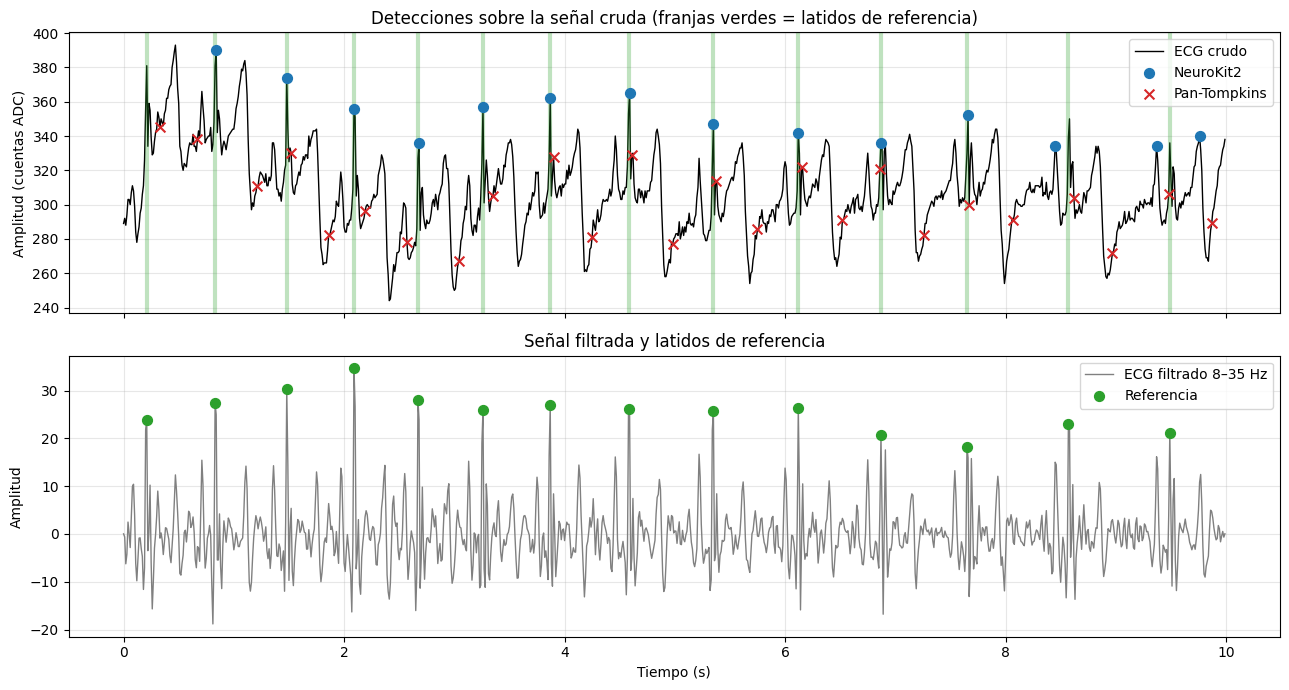

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

ax[0].plot(tiempo, signal, color="black", lw=1, label="ECG crudo")
ax[0].scatter(tiempo[r_nk], signal[r_nk], color="tab:blue", s=50, zorder=3, label="NeuroKit2")
ax[0].scatter(tiempo[r_pt], signal[r_pt], color="tab:red", marker="x", s=50, zorder=3, label="Pan-Tompkins")
for t in tiempo[r_ref]:
    ax[0].axvline(t, color="tab:green", alpha=0.3, lw=3)
ax[0].set_title("Detecciones sobre la señal cruda (franjas verdes = latidos de referencia)")
ax[0].set_ylabel("Amplitud (cuentas ADC)")
ax[0].legend(loc="upper right")
ax[0].grid(alpha=0.3)

ax[1].plot(tiempo, signal_bp, color="gray", lw=1, label="ECG filtrado 8–35 Hz")
ax[1].scatter(tiempo[r_ref], signal_bp[r_ref], color="tab:green", s=50, zorder=3, label="Referencia")
ax[1].set_title("Señal filtrada y latidos de referencia")
ax[1].set_xlabel("Tiempo (s)")
ax[1].set_ylabel("Amplitud")
ax[1].legend(loc="upper right")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**¿Cuál algoritmo detecta mejor los picos R?** (ver tabla y figura)

- Sobre la señal cruda, **NeuroKit2** es claramente mejor que los algoritmos de Detectors: detecta un número de latidos cercano al real y la mayoría coincide con la referencia. **Pan-Tompkins, Hamilton y Christov** casi duplican el número de latidos (muchos falsos positivos), porque confunden las ondas lentas de gran amplitud (onda T / deriva de línea base) con complejos QRS.
- La causa principal es la **baja frecuencia de muestreo (100 Hz)**: estos detectores fueron diseñados y ajustados para señales de 250–500 Hz, y a 100 Hz el QRS dura apenas 1–3 muestras. Además, en esta derivación el QRS tiene menor amplitud que la onda T, lo cual va en contra de los supuestos de los métodos basados en umbral de energía.
- Cuando se adapta el preprocesamiento (pasabanda 8–35 Hz que elimina la onda T), NeuroKit2 con el método `elgendi2010` alcanza el mejor desempeño (sensibilidad y VPP de 92,9 %). Entre los de Detectors, solo el *two-average* mejora claramente con el filtro; Pan-Tompkins no, porque su propio filtrado interno (5–15 Hz) a 100 Hz deja muy pocas muestras por QRS.

Conclusión: **NeuroKit2 es el que mejor detecta los picos R en este registro**, y la calidad de la detección depende más del preprocesamiento y de la frecuencia de muestreo que del algoritmo en sí.

2. Calcular la variabilidad de la frecuencia cardíaca (HRV) a partir de los picos R detectados

Para la HRV se usan los latidos validados (`r_ref`). Se calcula también la HRV con los picos de NeuroKit2 sobre la señal cruda para mostrar cómo un solo latido mal detectado distorsiona las métricas.

**Limitación importante:** el registro dura solo 10 s (14 latidos). Las guías de la Task Force (1996) recomiendan al menos 5 min para HRV de corto plazo, y los índices frecuenciales (LF, HF) y no lineales necesitan registros más largos. Por eso aquí solo se reportan índices en el **dominio del tiempo**, y deben interpretarse como un ejercicio metodológico, no como un resultado fisiológico concluyente.

In [6]:
# Intervalos RR en ms
rr_ref = np.diff(r_ref) / fs * 1000
rr_nk  = np.diff(r_nk)  / fs * 1000
print("RR (picos validados), ms:", np.round(rr_ref).astype(int))
print("RR (NeuroKit2 crudo), ms:", np.round(rr_nk).astype(int))

# HRV en el dominio del tiempo con NeuroKit2
hrv_ref = nk.hrv_time(r_ref, sampling_rate=fs)
hrv_nk  = nk.hrv_time(r_nk,  sampling_rate=fs)

cols = ["HRV_MeanNN", "HRV_SDNN", "HRV_RMSSD", "HRV_SDSD", "HRV_pNN50", "HRV_pNN20",
        "HRV_MedianNN", "HRV_MinNN", "HRV_MaxNN", "HRV_CVNN"]
comparacion_hrv = pd.DataFrame({
    "Picos validados": hrv_ref[cols].iloc[0],
    "NeuroKit2 (crudo)": hrv_nk[cols].iloc[0],
}).round(2)

fc_media = 60000 / np.mean(rr_ref)
print(f"\nFrecuencia cardíaca media (picos validados): {fc_media:.1f} lpm")
comparacion_hrv

RR (picos validados), ms: [620 650 610 580 590 610 710 770 770 750 780 920 920]
RR (NeuroKit2 crudo), ms: [640 610 590 580 610 720 760 770 750 790 790 920 390]

Frecuencia cardíaca media (picos validados): 84.1 lpm


,Picos validados,NeuroKit2 (crudo)
HRV_MeanNN,713.85,686.15
HRV_SDNN,117.16,134.14
HRV_RMSSD,56.57,162.25
HRV_SDSD,53.00,168.06
HRV_pNN50,23.08,23.08
HRV_pNN20,53.85,53.85
HRV_MedianNN,710.00,720.00
HRV_MinNN,580.00,390.00
HRV_MaxNN,920.00,920.00
HRV_CVNN,0.16,0.20


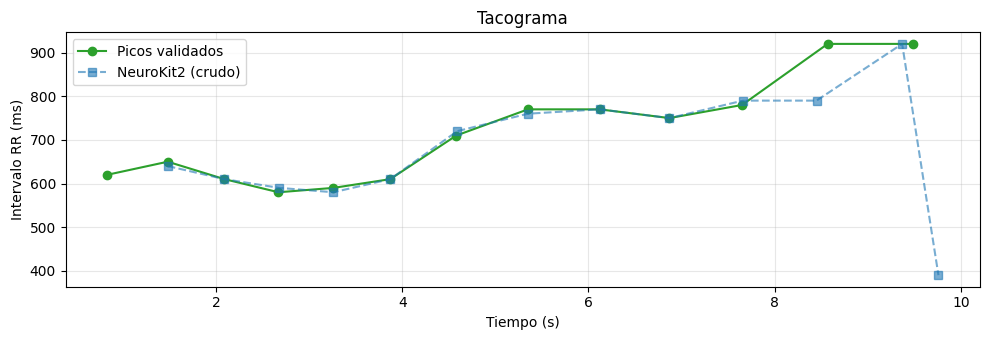

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(tiempo[r_ref[1:]], rr_ref, "o-", color="tab:green", label="Picos validados")
ax.plot(tiempo[r_nk[1:]], rr_nk, "s--", color="tab:blue", alpha=0.6, label="NeuroKit2 (crudo)")
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Intervalo RR (ms)")
ax.set_title("Tacograma")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Con los latidos validados los intervalos RR quedan entre 580 y 920 ms (FC media ≈ 84 lpm), con un alargamiento progresivo del RR a lo largo del registro, compatible con variación respiratoria o con la relajación del sujeto. Con los picos de NeuroKit2 sobre la señal cruda se omite el primer latido y aparece una detección falsa al final, que genera un RR de 390 ms: ese único error casi triplica el RMSSD (de 56,6 a 162,3 ms) y sube el SDNN de 117 a 134 ms. Esto muestra que **los errores de detección se propagan directamente a la HRV**, sobre todo a los índices basados en diferencias sucesivas (RMSSD, SDSD).

3. Investigar e implementar la función `get_time_domain_features` de la librería hrvanalysis para extraer características de HRV en el dominio del tiempo

`hrvanalysis` (paquete `hrv-analysis` en PyPI) trabaja con listas de intervalos RR en ms. El flujo recomendado por la librería es:

1. `remove_outliers`: elimina RR fuera de un rango fisiológico (aquí 300–2000 ms).
2. `interpolate_nan_values`: interpola los valores eliminados.
3. `remove_ectopic_beats` (regla de Malik): elimina RR que cambian más de un 20 % respecto al anterior (latidos ectópicos o detecciones erróneas).
4. `interpolate_nan_values` de nuevo.
5. `get_time_domain_features`: devuelve 16 índices: `mean_nni`, `sdnn`, `sdsd`, `nni_50`, `pnni_50`, `nni_20`, `pnni_20`, `rmssd`, `median_nni`, `range_nni`, `cvsd`, `cvnni`, `mean_hr`, `max_hr`, `min_hr`, `std_hr`.

Además se implementó la función manualmente con las mismas fórmulas, para verificar el resultado y como alternativa si la librería no se puede instalar.

In [8]:
def time_domain_manual(nn):
    """Réplica de hrvanalysis.get_time_domain_features (mismas fórmulas)."""
    nn = np.asarray(nn, dtype=float)
    diff_nn = np.diff(nn)
    hr = 60000 / nn
    rmssd = np.sqrt(np.mean(diff_nn ** 2))
    sdnn = np.std(nn, ddof=1)
    nni_50 = int(np.sum(np.abs(diff_nn) > 50))
    nni_20 = int(np.sum(np.abs(diff_nn) > 20))
    return {
        "mean_nni": np.mean(nn),
        "sdnn": sdnn,
        "sdsd": np.std(diff_nn),
        "nni_50": nni_50,
        "pnni_50": 100 * nni_50 / len(diff_nn),
        "nni_20": nni_20,
        "pnni_20": 100 * nni_20 / len(diff_nn),
        "rmssd": rmssd,
        "median_nni": np.median(nn),
        "range_nni": np.max(nn) - np.min(nn),
        "cvsd": rmssd / np.mean(nn),
        "cvnni": sdnn / np.mean(nn),
        "mean_hr": np.mean(hr),
        "max_hr": np.max(hr),
        "min_hr": np.min(hr),
        "std_hr": np.std(hr),
    }


def limpiar_rr(rr):
    """Preprocesamiento recomendado por hrvanalysis."""
    rr = list(rr)
    rr = remove_outliers(rr_intervals=rr, low_rri=300, high_rri=2000)
    rr = interpolate_nan_values(rr_intervals=rr, interpolation_method="linear")
    rr = remove_ectopic_beats(rr_intervals=rr, method="malik")
    rr = interpolate_nan_values(rr_intervals=rr, interpolation_method="linear")
    return np.asarray(rr, dtype=float)


try:
    from hrvanalysis import (get_time_domain_features, remove_outliers,
                             remove_ectopic_beats, interpolate_nan_values)
    HRVANALYSIS_OK = True
except ImportError:
    HRVANALYSIS_OK = False
    print("hrvanalysis no está instalada: se usa solo la implementación manual.")

if HRVANALYSIS_OK:
    nn_ref = limpiar_rr(rr_ref)
    nn_nk = limpiar_rr(rr_nk)
    tabla_hrv = pd.DataFrame({
        "hrvanalysis (validados)": get_time_domain_features(nn_ref),
        "manual (validados)": time_domain_manual(nn_ref),
        "hrvanalysis (NeuroKit2 crudo)": get_time_domain_features(nn_nk),
    })
else:
    tabla_hrv = pd.DataFrame({"manual (validados)": time_domain_manual(rr_ref)})

tabla_hrv.astype(float).round(2)

0 outlier(s) have been deleted.
0 ectopic beat(s) have been deleted with malik rule.
0 outlier(s) have been deleted.
1 ectopic beat(s) have been deleted with malik rule.


,hrvanalysis (validados),manual (validados),hrvanalysis (NeuroKit2 crudo)
mean_nni,713.85,713.85,726.92
sdnn,117.16,117.16,115.93
sdsd,50.74,50.74,48.71
nni_50,3.00,3.00,2.00
pnni_50,25.00,25.00,16.67
nni_20,7.00,7.00,6.00
pnni_20,58.33,58.33,50.00
rmssd,56.57,56.57,54.01
median_nni,710.00,710.00,750.00
range_nni,340.00,340.00,340.00


**Interpretación de los índices** (con los latidos validados):

- `mean_nni`, `median_nni` y `mean_hr`: intervalo RR típico y frecuencia cardíaca media.
- `sdnn` y `cvnni`: variabilidad global del ritmo (influencia simpática y parasimpática).
- `rmssd`, `sdsd`, `pnni_50`, `pnni_20`: variabilidad latido a latido (corto plazo), asociada principalmente a la actividad vagal (parasimpática).
- `range_nni`, `max_hr`, `min_hr`, `std_hr`: dispersión de la frecuencia cardíaca dentro del registro.

La implementación manual reproduce exactamente los valores de `hrvanalysis`, lo que valida las fórmulas. Al aplicar la limpieza sobre los RR de NeuroKit2 crudo, la regla de Malik elimina el RR erróneo de 390 ms y el RMSSD baja de 162 a 54 ms, muy cerca del valor con picos validados (56,6 ms). Es decir, **el preprocesamiento de los RR es indispensable antes de calcular HRV**, aunque solo corrige errores aislados: si la detección falla de forma sistemática (como con Pan-Tompkins aquí), la limpieza no alcanza. Dado que el registro es de solo 10 s, los valores son orientativos.

**5.5 Consulte tres aplicaciones clínicas del uso de ECG y EMG (seis aplicaciones en total, tres por cada tipo de señal), el tipo de registro y procesamiento que se utiliza en cada una de ellas.**

Imagen [7]

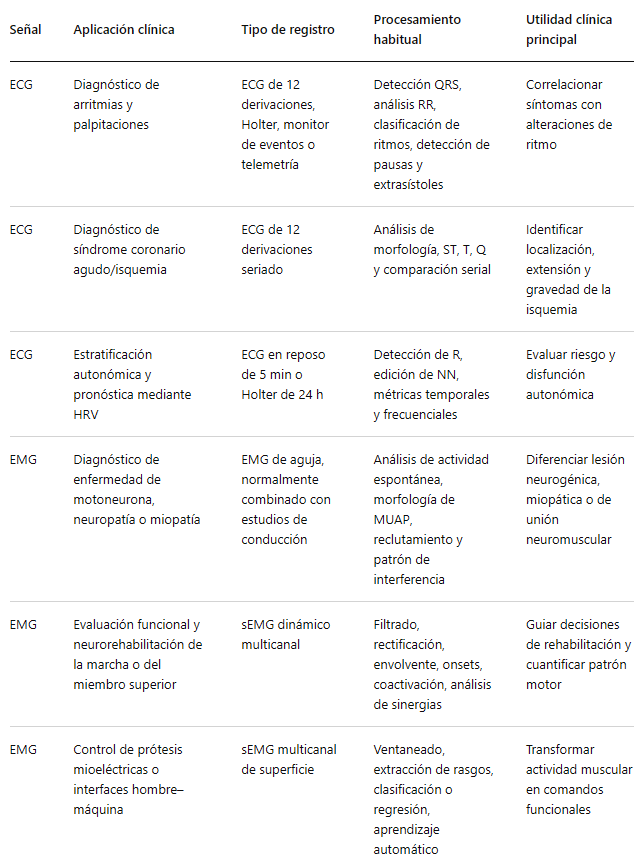

**5.6 Adjunte al menos tres conclusiones, y referencias bibliográficas apropiadas y suficientes (evitar el uso de páginas web y preferir el uso de artículos académicos)**

1. La detección de picos R depende más del preprocesamiento y de la frecuencia de muestreo que del algoritmo en sí. Sobre la señal cruda (100 Hz), NeuroKit2 obtuvo una sensibilidad y un VPP de 78,6 %, frente a 64,3 % y 36,0 % de Pan-Tompkins, que casi duplicó el número de latidos al confundir la onda T y la deriva de línea base con complejos QRS. Con un pasabanda de 8–35 Hz, NeuroKit2 (`elgendi2010`) llegó a 92,9 %. Los detectores clásicos fueron diseñados para 250–500 Hz y para QRS de mayor amplitud que la onda T, condiciones que no se cumplen en este registro [8], [9].

2. Los índices de HRV en el dominio del tiempo son muy sensibles a errores de detección. Un único latido mal ubicado (RR de 390 ms) casi triplicó el RMSSD (de 56,6 a 162,3 ms) y aumentó el SDNN de 117 a 134 ms. La limpieza de intervalos RR (eliminación de valores atípicos y regla de Malik) corrigió ese error aislado y llevó el RMSSD a 54 ms, por lo que es un paso indispensable antes de calcular HRV [10].

3. La implementación manual de `get_time_domain_features` reprodujo exactamente los valores de la librería `hrvanalysis`, lo que valida las fórmulas y permite entender cada índice. Sin embargo, el registro de 10 s (14 latidos) es insuficiente para una interpretación fisiológica de la HRV: las guías recomiendan al menos 5 min para índices de corto plazo, y los índices frecuenciales (LF, HF) no se pueden estimar con esta duración [10]. Para un análisis confiable se debería adquirir un registro más largo y con mayor frecuencia de muestreo (≥ 250 Hz), cuidando la preparación de la piel y la colocación de los electrodos.

**Referencias**

[1] Kligfield, P., Gettes, L. S., Bailey, J. J., Childers, R., Deal, B. J., Hancock, E. W., van Herpen, G., & Wagner, G. S. (2007). Recommendations for the standardization and interpretation of the electrocardiogram: Part I: The electrocardiogram and its technology: A scientific statement from the American Heart Association Electrocardiography and Arrhythmias Committee, Council on Clinical Cardiology; the American College of Cardiology Foundation; and the Heart Rhythm Society. Circulation, 115(10). https://doi.org/10.1161/CIRCULATIONAHA.106.180200

[2] Merletti, R., & Cerone, G. L. (2020). Tutorial. Surface EMG detection, conditioning and pre-processing: Best practices. Journal of Electromyography and Kinesiology, 54, 102440. https://doi.org/10.1016/j.jelekin.2020.102440

[3] Pérez-Riera, A. R., Barbosa-Barros, R., Daminello-Raimundo, R., & de Abreu, L. C. (2017). Main artifacts in electrocardiography. Annals of Noninvasive Electrocardiology, 23(2), e12494. https://doi.org/10.1111/anec.12494

[4] Lenis, G., Pilia, N., Loewe, A., Schulze, W. H. W., & Dössel, O. (2017). Comparison of baseline wander removal techniques considering the preservation of ST changes in the ischemic ECG: A simulation study. Computational and Mathematical Methods in Medicine, 2017, 9295029. https://doi.org/10.1155/2017/9295029

[5] Huigen, E., Peper, A., & Grimbergen, C. A. (2002). Investigation into the origin of the noise of surface electrodes. Medical and Biological Engineering and Computing, 40, 332–338. https://doi.org/10.1007/BF02344216

[6] Murphy, B. B., Scheid, B. H., Hendricks, Q., Apollo, N. V., Litt, B., & Vitale, F. (2021). Time evolution of the skin–electrode interface impedance under different skin treatments. Sensors, 21(15), 5210. https://doi.org/10.3390/s21155210

[7] Zimetbaum, P., & Goldman, A. (2010). Ambulatory arrhythmia monitoring: Choosing the right device. Circulation, 122(16), 1629–1636. https://doi.org/10.1161/CIRCULATIONAHA.109.925610

[8] J. Pan y W. J. Tompkins, “A real-time QRS detection algorithm,” IEEE Transactions on Biomedical Engineering, vol. BME-32, no. 3, pp. 230–236, 1985.

[9] D. Makowski, T. Pham, Z. J. Lau, J. C. Brammer, F. Lespinasse, H. Pham, C. Schölzel y S. H. A. Chen, “NeuroKit2: A Python toolbox for neurophysiological signal processing,” Behavior Research Methods, vol. 53, no. 4, pp. 1689–1696, 2021. https://doi.org/10.3758/s13428-020-01516-y

[10] Task Force of the European Society of Cardiology and the North American Society of Pacing and Electrophysiology (M. Malik, coord.), “Heart rate variability: Standards of measurement, physiological interpretation and clinical use,” European Heart Journal, vol. 17, no. 3, pp. 354–381, 1996.
